In [2]:
import os
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import openfermion as of
import quimb.tensor as qtn
from openfermion import InteractionOperator, get_fermion_operator, jordan_wigner
from openfermion.ops.representations import get_tensors_from_integrals

import ts_tools  # Fast k-commuting grouping, MPO construction and group variances.

In [3]:
# Parameters.
cutoff = 1e-3  # Drop Hamiltonian terms with |coefficient| below this (Ha).
k_values = [1, 2, 4, 11, 22]  # Block sizes for k-commuting grouping. k = 44 (full commutation) is left
                              # out for now: its large groups make the exact variances take ~1 h.
bond_dims = [16, 32, 64]  # DMRG bond-dimension schedule (last value repeats). Memory for the
                          # variances scales as bond_dim^2, so keep this <= 64 on a 16 GB machine.
nworkers = 4  # Processes for the group-variance calculation (each can use ~1.5 GB for the largest groups).
penalty_mu = 2.0  # Ha, strength of the (N - N_e)^2 penalty in DMRG.
epsilon = 1.6e-3  # Target precision in Ha (chemical accuracy, 1 kcal/mol).

# Intermediate results are saved here and reloaded on re-runs. Delete a file to recompute that step.
results_dir = f"results_cutoff_{cutoff:g}"
os.makedirs(results_dir, exist_ok=True)

## Get groups

In [7]:
h_data = np.load("../hamiltonians/ts.npz")
ecore = float(h_data["ECORE"])  # stored as a 0-d array; OpenFermion needs a scalar
h1 = h_data["H1"]
# H2 is in chemist notation, (pq|rs). get_tensors_from_integrals expects
# OpenFermion's MolecularData ordering, two_body_integrals[p,q,r,s] = (ps|qr).
h2 = h_data["H2"].transpose(0, 2, 3, 1)
one_body_tensor, two_body_tensor = get_tensors_from_integrals(h1, h2)
hamiltonian_op = InteractionOperator(
    constant=ecore,
    one_body_tensor=one_body_tensor,
    two_body_tensor=two_body_tensor
)
fermion_hamiltonian = get_fermion_operator(hamiltonian_op)
qubit_hamiltonian = jordan_wigner(fermion_hamiltonian)

Number of non-identity terms: 582430
min |c| = 3.875e-08, max |c| = 2.201e+00


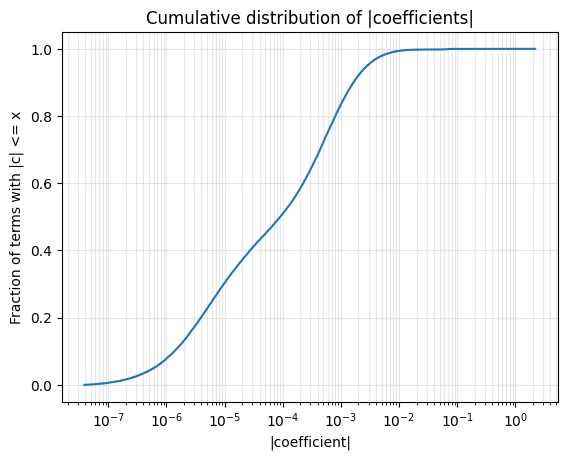

In [8]:
import matplotlib.pyplot as plt

# Absolute values of the Pauli-term coefficients (excluding the identity/constant term).
abs_coeffs = np.array(sorted(
    abs(coeff) for term, coeff in qubit_hamiltonian.terms.items() if term != ()
))
cdf = np.arange(1, len(abs_coeffs) + 1) / len(abs_coeffs)
print(f"Number of non-identity terms: {len(abs_coeffs)}")
print(f"min |c| = {abs_coeffs.min():.3e}, max |c| = {abs_coeffs.max():.3e}")

fig, ax = plt.subplots()
ax.step(abs_coeffs, cdf, where="post")
ax.set_xscale("log")
ax.set_xlabel("|coefficient|")
ax.set_ylabel("Fraction of terms with |c| <= x")
ax.set_title("Cumulative distribution of |coefficients|")
ax.grid(True, which="both", alpha=0.3)
plt.show()

In [ ]:
# Apply the cutoff to the qubit Hamiltonian (always keep the identity/constant term).
qubit_hamiltonian_cut = of.QubitOperator()
qubit_hamiltonian_cut.terms = {
    t: c for t, c in qubit_hamiltonian.terms.items() if t == () or abs(c) >= cutoff
}
dropped_l1 = sum(abs(c) for t, c in qubit_hamiltonian.terms.items() if t != () and abs(c) < cutoff)
print(f"Terms: {len(qubit_hamiltonian.terms)} -> {len(qubit_hamiltonian_cut.terms)}")
print(f"L1 norm of dropped terms: {dropped_l1:.4f} Ha")

with open(f"{results_dir}/ts_qubit_hamiltonian.pkl", "wb") as f:
    pickle.dump(qubit_hamiltonian_cut, f)

# Strings removed by the cutoff, kept on disk so they can be re-incorporated in the shot estimates.
dropped_terms = [t for t, c in qubit_hamiltonian.terms.items() if t != () and abs(c) < cutoff]
dropped_coeffs = np.array([qubit_hamiltonian.terms[t].real for t in dropped_terms])
with open(f"{results_dir}/ts_dropped_terms.pkl", "wb") as f:
    pickle.dump({"terms": dropped_terms, "coeffs": dropped_coeffs}, f)


In [ ]:
nqubits = of.count_qubits(qubit_hamiltonian_cut)
nelec = int(h_data["NELEC"])

# Non-identity terms sorted by decreasing |coefficient|, bit-packed for fast commutation checks.
terms, coeffs, x, z = ts_tools.qubit_operator_to_arrays(qubit_hamiltonian_cut)
assert np.max(np.abs(coeffs.imag)) < 1e-12
coeffs = coeffs.real
print(f"{nqubits} qubits, {nelec} electrons, {len(terms)} non-identity terms")

In [ ]:
# Sorted-insertion k-commuting grouping (same algorithm as kcommute.get_si_sets, numba-compiled).
groups = {}
for k in k_values:
    start = time.time()
    groups[k] = ts_tools.k_commuting_groups(x, z, nqubits, k)
    print(f"k = {k:2d}: {len(groups[k]):6d} groups ({time.time() - start:.1f} s)")

In [ ]:
# Groups are saved as arrays of indices into `terms`/`coeffs`.
with open(f"{results_dir}/ts_groups.pkl", "wb") as f:
    pickle.dump({"terms": terms, "coeffs": coeffs, "groups": groups}, f)

## Ground state using DMRG

The MPO is built from the fermionic Hamiltonian, with the same cutoff applied to the (normal-ordered) fermionic coefficients and the Jordan-Wigner transformation done inside quimb (verified to match OpenFermion's convention). The resulting ground state is used as an approximation to the ground state of the qubit Hamiltonian with the Pauli-level cutoff. Building the MPO takes ~25 min, so it is cached.

quimb's DMRG uses no particle-number symmetry, so a penalty $\mu (\hat N - N_e)^2$ is added to keep the state in the $N_e$-electron sector (this does not change eigenstates in that sector since $[H, \hat N] = 0$). DMRG starts from Hartree-Fock plus a small random perturbation: the pure HF product state is a fixed point of the two-site update because of number conservation, and a fully random start converges to a poor local minimum.

In [ ]:
mpo_file = f"{results_dir}/ts_mpo.pkl"
if os.path.exists(mpo_file):
    with open(mpo_file, "rb") as f:
        mpo_data = pickle.load(f)
else:
    start = time.time()
    fermion_hamiltonian_no = of.normal_ordered(fermion_hamiltonian)
    constant = fermion_hamiltonian_no.terms.get((), 0.0).real
    fermion_hamiltonian_cut = of.FermionOperator()
    fermion_hamiltonian_cut.terms = {
        t: c.real for t, c in fermion_hamiltonian_no.terms.items() if t != () and abs(c) >= cutoff
    }
    print(f"Fermionic terms after cutoff: {len(fermion_hamiltonian_cut.terms)}")
    mpo = ts_tools.fermion_operator_to_mpo(fermion_hamiltonian_cut, nqubits)
    mpo_data = {"mpo": mpo, "constant": constant}
    with open(mpo_file, "wb") as f:
        pickle.dump(mpo_data, f)
    print(f"Built MPO in {time.time() - start:.0f} s")

mpo, constant = mpo_data["mpo"], mpo_data["constant"]
print(f"MPO max bond dimension: {mpo.max_bond()}")

In [ ]:
gs_file = f"{results_dir}/ts_ground_state.pkl"
if os.path.exists(gs_file):
    with open(gs_file, "rb") as f:
        gs_data = pickle.load(f)
else:
    dmrg_mpo = mpo.add_MPO(ts_tools.number_penalty_mpo(nqubits, nelec, mu=penalty_mu))

    # Hartree-Fock (lowest nelec spin-orbitals occupied, |1> = occupied in JW) plus a small random perturbation.
    hf = qtn.MPS_computational_state("1" * nelec + "0" * (nqubits - nelec), dtype="float64")
    noise = qtn.MPS_rand_state(nqubits, bond_dim=bond_dims[0], dtype="float64", seed=0)
    p0 = hf.add_MPS(noise.multiply(1e-2))
    p0.compress(max_bond=bond_dims[0])
    p0.normalize()

    dmrg = qtn.DMRG2(dmrg_mpo, bond_dims=bond_dims, cutoffs=1e-10, p0=p0)
    start = time.time()
    dmrg.solve(tol=1e-6, max_sweeps=10, verbosity=1)
    gs_data = {
        "psi": dmrg.state,
        "energy": dmrg.energy.real + constant,
        "sweep_energies": [e.real + constant for e in dmrg.energies],
        "bond_dims": bond_dims,
        "time": time.time() - start,
    }
    with open(gs_file, "wb") as f:
        pickle.dump(gs_data, f)

psi = gs_data["psi"]
psi_arrays = ts_tools.mps_to_arrays(psi)
n_expect = sum((1 - ts_tools.pauli_expectation(psi_arrays, ((i, "Z"),)).real) / 2 for i in range(nqubits))
print(f"DMRG energy: {gs_data['energy']:.6f} Ha (max bond {psi.max_bond()}, {gs_data['time']:.0f} s)")
print(f"<N> = {n_expect:.6f} (expected {nelec})")

## Shot counts for each grouping.

For each grouping, the shots needed to estimate $\langle H \rangle$ to precision $\epsilon$ with optimal shot allocation are $N = \left(\sum_g \sqrt{\mathrm{Var}_\psi(H_g)}\right)^2 / \epsilon^2$. Each group variance is computed exactly from the MPS. Groups that appear for several values of $k$ are only computed once.

In [ ]:
# Free large objects that are no longer needed (DMRG environments alone are several GB)
# before the memory-heavy variance step.
import gc
for name in ["dmrg", "dmrg_mpo", "mpo", "mpo_data", "qubit_hamiltonian", "fermion_hamiltonian", "hamiltonian_op"]:
    globals().pop(name, None)
gc.collect()

cache_file = f"{results_dir}/ts_variance_cache.pkl"
cache = {}
if os.path.exists(cache_file):
    with open(cache_file, "rb") as f:
        saved = pickle.load(f)
    if np.isclose(saved["energy"], gs_data["energy"]):  # Only reuse variances for the same ground state.
        cache = saved["variances"]

shot_results = {}
for k in k_values:
    start = time.time()
    variances = ts_tools.group_variances(groups[k], terms, coeffs, nqubits, psi, cache=cache, nworkers=nworkers)
    with open(cache_file, "wb") as f:
        pickle.dump({"energy": gs_data["energy"], "variances": cache}, f)
    shot_results[k] = {
        "ngroups": len(groups[k]),
        "variances": variances,
        "shots": ts_tools.shots_from_variances(variances, epsilon),
    }
    print(f"k = {k:2d}: {len(groups[k]):6d} groups, {shot_results[k]['shots']:.3e} shots ({time.time() - start:.0f} s)")

with open(f"{results_dir}/ts_shotcounts.pkl", "wb") as f:
    pickle.dump({"epsilon": epsilon, "cutoff": cutoff, "results": shot_results}, f)

## Re-incorporating the cut-off strings

Same scheme as `../cutoff_reincorporation/lih_cutoff.ipynb`: all cut-off **Z-only** strings are measured in one group and every other cut-off string is measured **individually**. These extra groups don't depend on $k$, so their $\sum_g \sqrt{\mathrm{Var}(H_g)}$ is computed once and added to the kept-string sum for each $k$:
$N_k = \left(\sum_{g \in \text{kept}, k} \sqrt{\mathrm{Var}(H_g)} + \sum_{g \in \text{cut}} \sqrt{\mathrm{Var}(H_g)}\right)^2 / \epsilon^2$.
For a single string, $\mathrm{Var}(cP) = c^2 (1 - \langle P \rangle^2)$.

In [ ]:
with open(f"{results_dir}/ts_dropped_terms.pkl", "rb") as f:
    dropped = pickle.load(f)
dropped_terms, dropped_coeffs = dropped["terms"], dropped["coeffs"]

z_only = np.array([all(p == "Z" for _, p in t) for t in dropped_terms])
dropped_groups = [np.array([i]) for i in np.flatnonzero(~z_only)]
if z_only.any():
    dropped_groups.append(np.flatnonzero(z_only))
print(f"Cut-off strings: {len(dropped_terms)} ({z_only.sum()} Z-only in one group, "
      f"{(~z_only).sum()} measured individually) -> {len(dropped_groups)} extra groups")

dropped_cache_file = f"{results_dir}/ts_dropped_variance_cache.pkl"
dropped_cache = {}
if os.path.exists(dropped_cache_file):
    with open(dropped_cache_file, "rb") as f:
        saved = pickle.load(f)
    if np.isclose(saved["energy"], gs_data["energy"]):
        dropped_cache = saved["variances"]

start = time.time()
dropped_variances = ts_tools.group_variances(
    dropped_groups, dropped_terms, dropped_coeffs, nqubits, psi,
    cache=dropped_cache, nworkers=os.cpu_count(), chunksize=2000,  # Single strings: cheap and low-memory.
)
with open(dropped_cache_file, "wb") as f:
    pickle.dump({"energy": gs_data["energy"], "variances": dropped_cache}, f)
sqrt_sum_dropped = np.sum(np.sqrt(np.clip(dropped_variances, 0.0, None)))
print(f"Cut-off strings: sum of sqrt(Var) = {sqrt_sum_dropped:.4f} Ha ({time.time() - start:.0f} s)")

reincorporated_results = {}
for k, r in shot_results.items():
    sqrt_sum_kept = np.sum(np.sqrt(np.clip(r["variances"], 0.0, None)))
    reincorporated_results[k] = {
        "ngroups": r["ngroups"] + len(dropped_groups),
        "sqrt_sum_kept": sqrt_sum_kept,
        "sqrt_sum_dropped": sqrt_sum_dropped,
        "shots": (sqrt_sum_kept + sqrt_sum_dropped) ** 2 / epsilon**2,
    }
    print(f"k = {k:2d}: {r['shots']:.3e} shots (kept strings only) -> "
          f"{reincorporated_results[k]['shots']:.3e} shots (cut-off strings re-incorporated)")

with open(f"{results_dir}/ts_shotcounts_reincorporated.pkl", "wb") as f:
    pickle.dump({"epsilon": epsilon, "cutoff": cutoff, "results": reincorporated_results}, f)

In [4]:
# Load saved results so the plot can be made without re-running the expensive cells
# (only the imports and parameters cells need to have been run).
with open(f"{results_dir}/ts_groups.pkl", "rb") as f:
    groups_data = pickle.load(f)
nqubits = 1 + max(q for term in groups_data["terms"] for q, _ in term)

shotcounts_file = f"{results_dir}/ts_shotcounts.pkl"
if os.path.exists(shotcounts_file):
    with open(shotcounts_file, "rb") as f:
        shot_results = pickle.load(f)["results"]
else:
    # Rebuild from the groups and the variance cache for every k whose groups are all cached.
    with open(f"{results_dir}/ts_variance_cache.pkl", "rb") as f:
        variance_cache = pickle.load(f)["variances"]
    shot_results = {}
    for k, k_groups in groups_data["groups"].items():
        keys = [tuple(sorted(int(j) for j in g)) for g in k_groups]
        if all(key in variance_cache for key in keys):
            variances = np.array([variance_cache[key] for key in keys])
            shot_results[k] = {
                "ngroups": len(k_groups),
                "variances": variances,
                "shots": ts_tools.shots_from_variances(variances, epsilon),
            }
        else:
            print(f"k = {k}: variances not all computed yet, skipping")
for k, r in shot_results.items():
    print(f"k = {k:2d}: {r['ngroups']:6d} groups, {r['shots']:.3e} shots")


reincorporated_file = f"{results_dir}/ts_shotcounts_reincorporated.pkl"
reincorporated_results = {}
if os.path.exists(reincorporated_file):
    with open(reincorporated_file, "rb") as f:
        reincorporated_results = pickle.load(f)["results"]
for k, r in reincorporated_results.items():
    print(f"k = {k:2d}: {r['shots']:.3e} shots with cut-off strings re-incorporated")


k =  1:  23814 groups, 3.725e+09 shots
k =  2:  21183 groups, 3.428e+09 shots
k =  4:  17559 groups, 2.790e+09 shots
k = 11:   9552 groups, 1.246e+09 shots
k = 22:   3453 groups, 5.620e+08 shots
k =  1: 1.305e+10 shots with cut-off strings re-incorporated
k =  2: 1.249e+10 shots with cut-off strings re-incorporated
k =  4: 1.125e+10 shots with cut-off strings re-incorporated
k = 11: 7.835e+09 shots with cut-off strings re-incorporated
k = 22: 5.918e+09 shots with cut-off strings re-incorporated


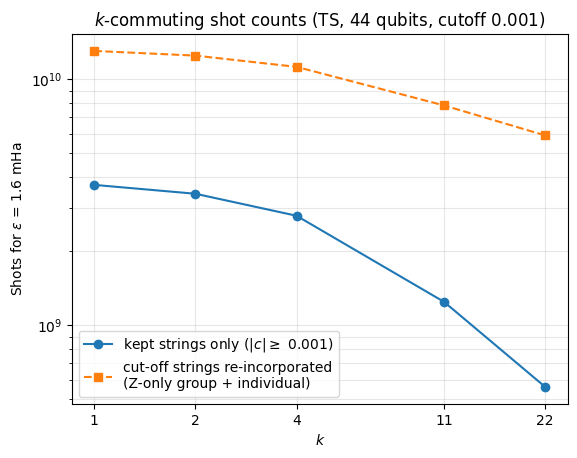

In [5]:
ks = sorted(shot_results)

fig, ax = plt.subplots()
ax.plot(ks, [shot_results[k]["shots"] for k in ks], "o-", label=f"kept strings only ($|c| \\geq$ {cutoff:g})")
ks_re = sorted(reincorporated_results)
if ks_re:
    ax.plot(ks_re, [reincorporated_results[k]["shots"] for k in ks_re], "s--",
            label="cut-off strings re-incorporated\n(Z-only group + individual)")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(ks, [str(k) for k in ks])
ax.set_xlabel("$k$")
ax.set_ylabel(f"Shots for $\\epsilon$ = {epsilon * 1e3:g} mHa")
ax.set_title(f"$k$-commuting shot counts (TS, {nqubits} qubits, cutoff {cutoff:g})")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.savefig(f"{results_dir}/ts_shots_vs_k.pdf", bbox_inches="tight")
plt.show()
